# Project 1

Alexander Matteson

GitHub Link: 

In [1]:
# imports: 
import rawpy
import imageio.v3 as iio
import os
from fractions import Fraction
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2
from matplotlib.colors import ListedColormap
import sys
from scipy.optimize import brentq
from scipy.special import erf
import matplotlib
import psu_imaging as psu
import sys
from pathlib import Path
from scipy.stats import theilslopes
from pathlib import Path
import exifread
import math
from scipy.signal import windows

## Meausrements described in assignment:

1. Geometry: intrinsics and lens distortion. Calibrate with the printed checkerboard using cv2.calibrateCamera. Report focal length in pixels and in millimetres, principal point, the radial and tangential distortion coefficients, and the RMS reprojection error. Show an undistorted image next to the original with a straight edge in frame, so the correction is visible. Lecture 2.

For this we will need the checker board .dng captures and the code from assignment 1 and 2.

(1512, 2016) uint8


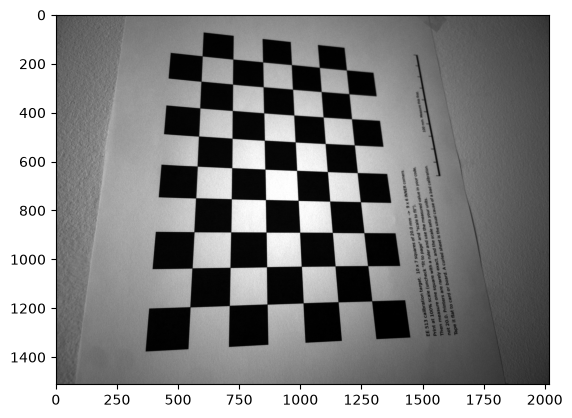

In [2]:
# load the checker board images (note: we just select the green images planes from the bayer mosaic)
FOLDER_checker = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards" #<- folder with the captures

# function:
def load_green(path, as_8bit=True):
    """Raw DNG -> average of the two green sites per 2x2 block (half-size array)."""
    with rawpy.imread(path) as raw:
        bayer = raw.raw_image_visible.astype(np.float32)
        black = np.array(raw.black_level_per_channel, dtype=np.float32)
        bayer -= black[raw.raw_colors_visible]      # subtract black level per colour
    bayer = np.clip(bayer, 0, None)

    H, W = (bayer.shape[0] // 2) * 2, (bayer.shape[1] // 2) * 2   # trim to even size
    bayer = bayer[:H, :W]

    g1 = bayer[0::2, 1::2]    # G1: row 0, col 1 of each block
    g2 = bayer[1::2, 0::2]    # G2: row 1, col 0 of each block
    g = (g1 + g2) / 2.0

    if not as_8bit:
        return g
    lo, hi = np.percentile(g, 0.5), np.percentile(g, 99.5)
    return np.clip((g - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

# quick check
path = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards\Target1.dng"
gray = load_green(path)
print(gray.shape, gray.dtype)

plt.imshow(gray, cmap="gray"); plt.show()

In [3]:
# Load the images of the test target: these are the raw .dng images and we will use only the green channel
FOLDER_checker = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards" 
NUM_IMGs = 15 # how many?
pattern_size = (9, 6)
SQUARE_MM = 19.0   # in mm the measured square size on the printed targets

# 3D corner positions for one board: (0,0,0), (s,0,0), (2s,0,0) ... on the Z=0 plane 
objp = np.zeros((pattern_size[0] * pattern_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1, 2)
objp *= SQUARE_MM

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

objpoints = []   # 3D points in real-world space
imgpoints = []   # 2D points in the image plane
image_size = None

# load the images:
for i in range(NUM_IMGs):
    path = FOLDER_checker + "\\" + f"Target{i+1}.dng"
    #print(path)
    img = load_green(path)
    image_size = img.shape[::-1]        # (width, height), needed by calibrateCamera
    #print(image_size)
    # find checkerboard corners
    ret, corners = cv2.findChessboardCorners(img, pattern_size, None)

    if ret == True:
        #print(path)
        corners = cv2.cornerSubPix(img, corners, (11, 11), (-1, -1), criteria)
        objpoints.append(objp) # saving the obj points and corners
        imgpoints.append(corners)
    else:
        print("FAILED: " + path)
    
    
# use calibrate camera from cv2
rms, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, image_size, None, None, flags=cv2.CALIB_FIX_K3)

# print the rms
print("RMS = " + str(rms))

# distortion corfficients (four)
k1, k2, p1, p2, k3 = dist.ravel()[:5] 
print("k1 = " + str(k1))
print("k2 = " + str(k2))
print("p1 = " + str(p1))
print("p2 = " + str(p2))

fx, fy = mtx[0, 0], mtx[1, 1] # <- the focal lengths you will need this as a read out on spec sheet
cx, cy = mtx[0, 2], mtx[1, 2] # <- the principle you will need this as a read out on spec sheet

print("Array size (w, h):", image_size)
print(f"fx = {fx:.2f} px, fy = {fy:.2f} px")

print(f"Principal point: cx = {cx:.2f} px, cy = {cy:.2f} px")

RMS = 0.4146021385713117
k1 = 0.08309975862164776
k2 = -0.14912274966820913
p1 = -0.0012237626437150884
p2 = -0.00036844270851860606
Array size (w, h): (2016, 1512)
fx = 1551.70 px, fy = 1554.49 px
Principal point: cx = 998.82 px, cy = 745.37 px


In [4]:
# get the pixek pitch so that you can update the above values to be in umits of mm (or um):
# from the dng files properties:
f_mm = 4 # mm
# use the fpx value from our calculations:
fpx = (mtx[0, 0] + mtx[1, 1]) / 2          # mean of fx and fy, px
pitch1_um = 1000 * f_mm / fpx              # micrometers per pixel

print(f"Pitch from calibration: {pitch1_um:.3f} µm")
pitch_mm = pitch1_um/1000
# use from above to calculate the focal length in mm :
print(f"fx = {fx*pitch_mm:.2f} mm, fy = {fy*pitch_mm:.2f} mm")
# now princple point in mm:
print(f"Principal point: cx = {cx*pitch_mm:.2f} mm, cy = {cy*pitch_mm:.2f} m")

# compare to the pitch calculated using manufacturer specs: 
f_35mm = 26
# method 2: 
crop = f_35mm / f_mm                       # crop factor
sensor_diag_mm = 43.3 / crop               # physical sensor diagonal, mm
w, h = image_size                          # the green-array size you calibrated at
img_diag_px = np.hypot(w, h)
pitch2_um = 1000 * sensor_diag_mm / img_diag_px
print(f"Pitch from crop factor (route 2): {pitch2_um:.3f} um")

Pitch from calibration: 2.576 µm
fx = 4.00 mm, fy = 4.00 mm
Principal point: cx = 2.57 mm, cy = 1.92 m
Pitch from crop factor (route 2): 2.643 um


Image size: (2016, 1512) | calibration size: (2016, 1512)


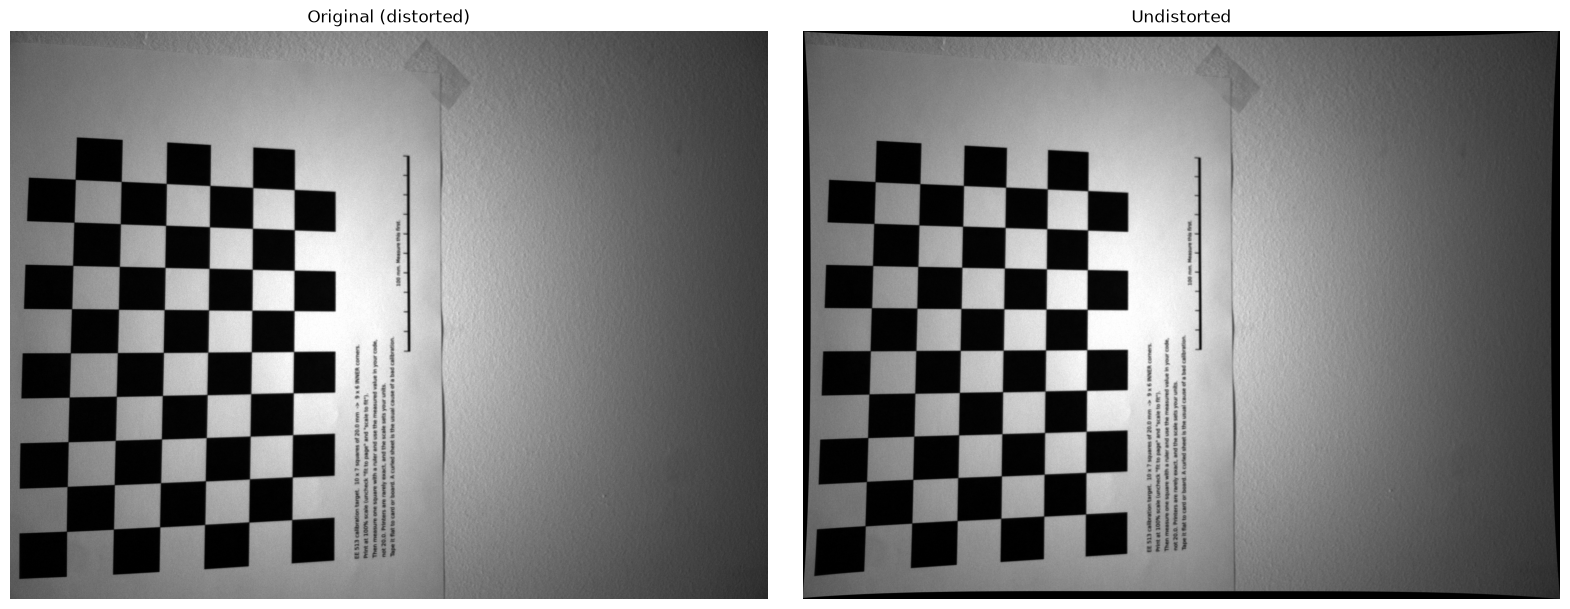

In [5]:
# compare a distored and undistored image: 
path = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards\Target7.dng"   # image with the long straight edge
img = load_green(path)                 # same loader as the calibration images
h, w = img.shape
print("Image size:", (w, h), "| calibration size:", image_size)   # these must match

# alpha=1 keeps every source pixel (black borders appear), so the edge near the
# frame boundary isn't cropped away. alpha=0 would crop to the valid region.
newmtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), alpha=1, newImgSize=(w, h))
und = cv2.undistort(img, mtx, dist, None, newmtx)

# side by side
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(img, cmap="gray");  ax[0].set_title("Original (distorted)")
ax[1].imshow(und, cmap="gray");  ax[1].set_title("Undistorted")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("undistort_side_by_side.png", dpi=150)
plt.show()


row 0: mean (x, y) = [162. 861.]   before = 1.211 px, after = 0.126 px
row 1: mean (x, y) = [287. 860.]   before = 0.257 px, after = 0.205 px
row 2: mean (x, y) = [408. 860.]   before = 0.649 px, after = 0.195 px
row 3: mean (x, y) = [527. 859.]   before = 0.888 px, after = 0.227 px
row 4: mean (x, y) = [642. 859.]   before = 0.965 px, after = 0.173 px
row 5: mean (x, y) = [755. 858.]   before = 1.053 px, after = 0.327 px


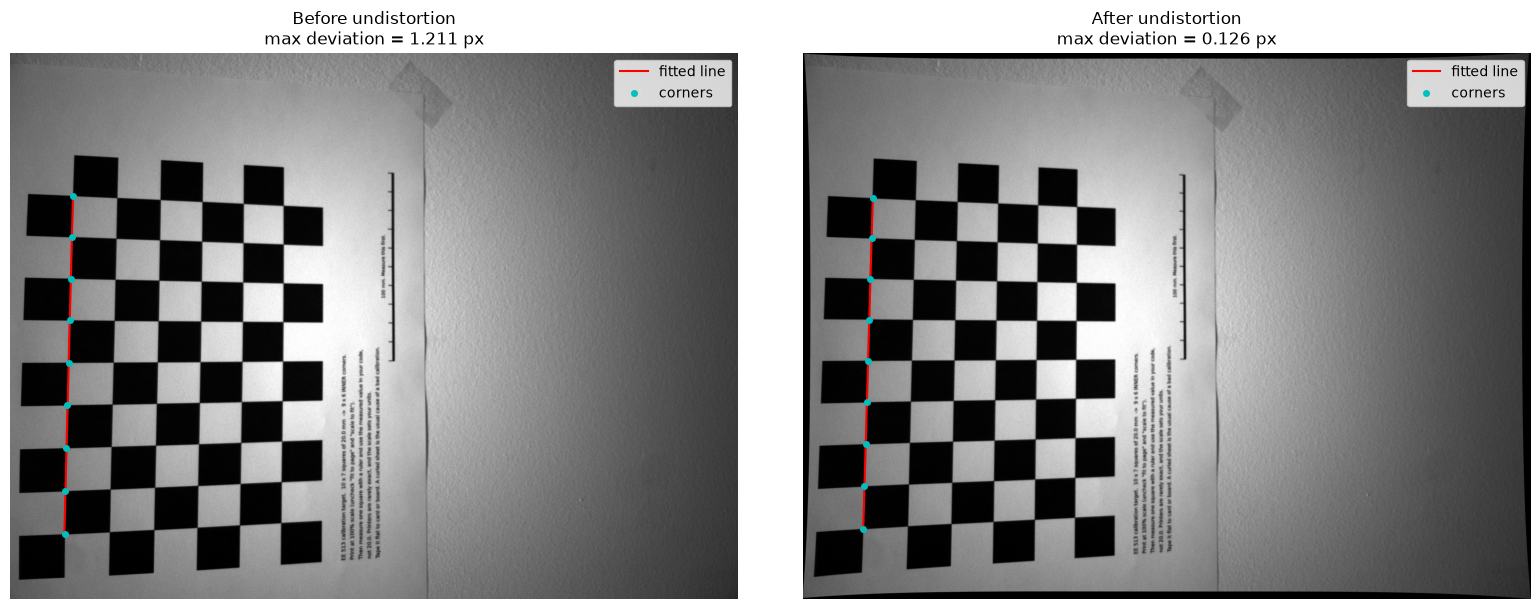

Max perpendicular deviation: before = 1.211 px, after = 0.126 px


In [6]:
# from Homework 2 display a line throught the squares adn quantify
ret, corners = cv2.findChessboardCorners(img, pattern_size, None)
assert ret, "corners not found"
corners = cv2.cornerSubPix(img, corners, (11, 11), (-1, -1), criteria)

# corners come back row by row: shape (rows, cols, 2) = (6, 9, 2)
grid = corners.reshape(pattern_size[1], pattern_size[0], 2)

# undistort the same points (P=newmtx matches the undistorted image from before)
newmtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), alpha=1, newImgSize=(w, h))
und_corners = cv2.undistortPoints(corners, mtx, dist, P=newmtx)
und_grid = und_corners.reshape(pattern_size[1], pattern_size[0], 2)

def max_perp_dev(pts):
    """Fit a line (total least squares) and return the max perpendicular distance in px."""
    pts = pts.reshape(-1, 2).astype(np.float64)
    c = pts.mean(axis=0)
    _, _, vt = np.linalg.svd(pts - c)
    normal = vt[1]                      # unit vector perpendicular to the best-fit line
    return np.abs((pts - c) @ normal).max()

# which row is bottom-left? print each row's mean position (x, y); y grows downward
for r in range(grid.shape[0]):
    print(f"row {r}: mean (x, y) = {grid[r].mean(axis=0).round(0)}   "
          f"before = {max_perp_dev(grid[r]):.3f} px, after = {max_perp_dev(und_grid[r]):.3f} px")

ROW = 0    # <- set to the row nearest the bottom-left corner (largest y, smallest x)
before = max_perp_dev(grid[ROW])
after = max_perp_dev(und_grid[ROW])

und = cv2.undistort(img, mtx, dist, None, newmtx)

def fit_line(pts):
    """Total-least-squares line: returns points, centroid, unit direction, signed perpendicular distances."""
    pts = pts.reshape(-1, 2).astype(np.float64)
    c = pts.mean(axis=0)
    _, _, vt = np.linalg.svd(pts - c)
    direction, normal = vt[0], vt[1]
    return pts, c, direction, (pts - c) @ normal

def line_ends(pts, c, d):
    t = (pts - c) @ d
    return np.array([c + t.min() * d, c + t.max() * d])

pb, cb, db, resid_b = fit_line(grid[ROW])
pa, ca, da, resid_a = fit_line(und_grid[ROW])

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, im, pts, c, d, title, dev in [
        (ax[0], img, pb, cb, db, "Before undistortion", resid_b),
        (ax[1], und, pa, ca, da, "After undistortion", resid_a)]:
    a.imshow(im, cmap="gray")
    ends = line_ends(pts, c, d)
    a.plot(ends[:, 0], ends[:, 1], "r-", lw=1.5, label="fitted line")
    a.plot(pts[:, 0], pts[:, 1], "c.", ms=8, label="corners")
    a.set_title(f"{title}\nmax deviation = {np.abs(dev).max():.3f} px")
    a.legend(loc="upper right")
    a.axis("off")

plt.tight_layout()
plt.savefig("row_line_fit_before_after.png", dpi=150)
plt.show()

print(f"Max perpendicular deviation: before = {np.abs(resid_b).max():.3f} px, after = {np.abs(resid_a).max():.3f} px")

## Spatial resolution: MTF

STEPS:
Measurement:
1. Capture a slanted edge, linear (raw, .dng file) 
2. Find the edge position in each row to sub-pixel precision
3. Fit a line through those positions, so one bad row cannot hurt you
4. Project every pixel onto the edge normal, bin at about 1/4 pixel
5. That is the edge spread function; differentiate it for the line spread function
6. Window it, take the magnitude of its Fourier transform, normalize to 1 at DC That is the MTF

Validtion: 
1. generate synthetic edge
2. Measure the MTF and MTF50 on that synthetc edge using the measuremen code
3. Compare result to known analytic values for the synthic edge
4. Report if our method retunrs a value that agrees with the analytic value

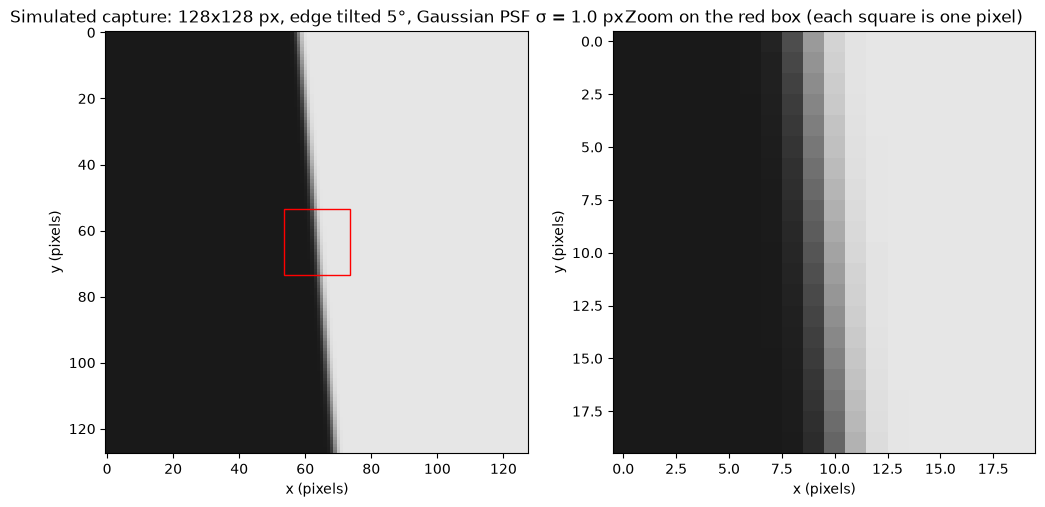

In [7]:
# Validation code:
# 1: generate a synthetic edge (tilt a step edge by 5 degrees)
W = H = 128            # image size in pixels
theta = np.deg2rad(5)  # tilt of the edge from vertical
sigma = 1.0            # Gaussian PSF standard deviation, pixels
dark, bright = 0.1, 0.9
 
# pixel-centre coordinates, origin at the image centre
x, y = np.meshgrid(np.arange(W) - (W - 1) / 2, np.arange(H) - (H - 1) / 2)
 
# signed perpendicular distance from each pixel centre to the tilted edge line
d = x * np.cos(theta) - y * np.sin(theta)

# 2: convolve with a gaussian blur
img_synthetic = dark + (bright - dark) * 0.5 * (1 + erf(d / (sigma * np.sqrt(2))))

# add a zoomed in figure of the line to appreciate the blur
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img_synthetic, cmap="gray", vmin=0, vmax=1)
ax[0].set_title(f"Simulated capture: {W}x{H} px, edge tilted 5°, Gaussian PSF σ = {sigma} px")
r = (slice(54, 74), slice(54, 74))
ax[0].add_patch(plt.Rectangle((54 - .5, 54 - .5), 20, 20, fill=False, ec="r"))
ax[1].imshow(img_synthetic[r], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
ax[1].set_title("Zoom on the red box (each square is one pixel)")
for a in ax:
    a.set_xlabel("x (pixels)"); a.set_ylabel("y (pixels)")


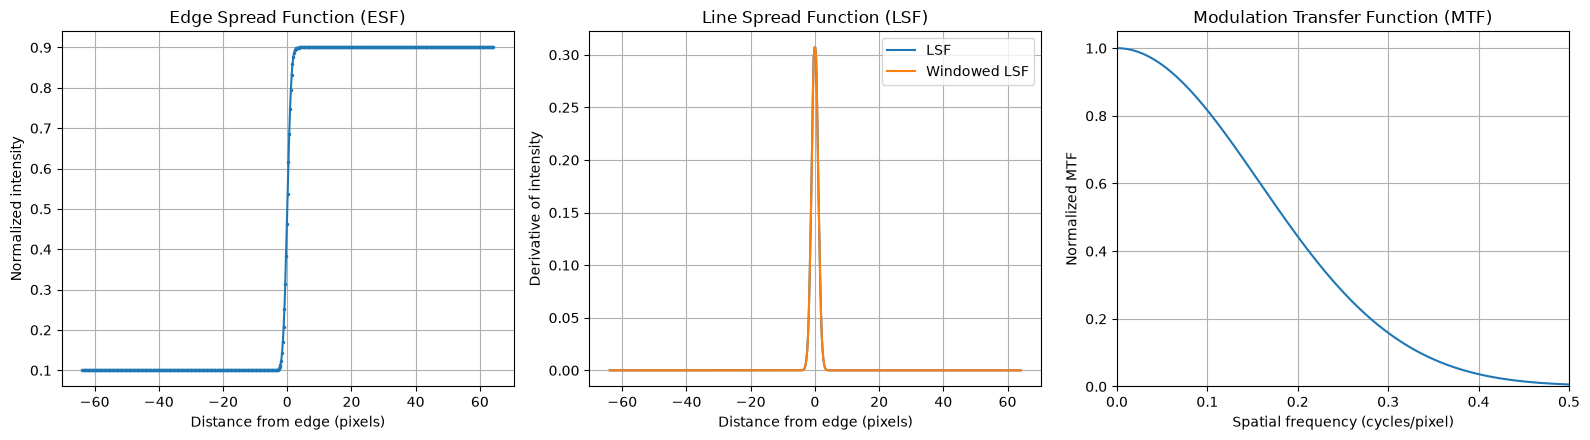

In [8]:
# 1. image of slanted edge:

img_synthetic = img_synthetic # this is the image of the slanted edge
ncols, nrows = img_synthetic.shape[:2]
# 2. find the edge in the img

def FindEdges(img):
    ncols, nrows = img.shape[:2]
    edge_rows = []
    edge_cols = []
    
    for y in range(nrows):
        row = img[y, :]
    
        # First derivative along the horizontal direction.
        grad = np.gradient(row)
    
        # Find the strongest edge in this row.
        # Use absolute gradient to support either edge polarity.
        x_peak = np.argmax(np.abs(grad))
    
        # Subpixel peak localization using a parabolic fit.
        # Fit the peak and its two neighboring samples.
        if 0 < x_peak < ncols - 1:
            g = np.abs(grad)
            left = g[x_peak - 1]
            center = g[x_peak]
            right = g[x_peak + 1]
    
            denom = left - 2 * center + right
    
            if abs(denom) > 1e-12:
                offset = 0.5 * (left - right) / denom
                offset = np.clip(offset, -1, 1)
                x_subpixel = x_peak + offset
            else:
                x_subpixel = float(x_peak)
        else:
            x_subpixel = float(x_peak)
    
        edge_rows.append(y)
        edge_cols.append(x_subpixel)

    edge_rows = np.asarray(edge_rows, dtype=float)
    edge_cols = np.asarray(edge_cols, dtype=float)
    return edge_rows, edge_cols

edge_rows, edge_cols = FindEdges(img_synthetic)

# 3. fit a line through that edge points
# Model: x_edge = slope * y + intercept
slope, intercept, _, _ = theilslopes(edge_cols, edge_rows) # use edge points for the 

fitted_cols = slope * edge_rows + intercept

# 4. Project every pixel onto the edge normal -> edge spread function
# The fitted edge is x = slope*y + intercept.
# Signed perpendicular distance from each pixel to the edge:
# d = (x - slope*y - intercept) / sqrt(1 + slope**2)

yy, xx = np.indices(img_synthetic.shape, dtype=float)

distance = (
    xx - slope * yy - intercept
) / np.sqrt(1 + slope**2)

# Oversampling factor: 4 means 0.25 pixel per bin.
oversampling = 4
bin_width = 1.0 / oversampling

# Keep the full available distance range.
d_min = np.floor(distance.min() / bin_width) * bin_width
d_max = np.ceil(distance.max() / bin_width) * bin_width

bin_edges = np.arange(
    d_min, d_max + bin_width * 1.01, bin_width
)

# Bin centers.
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Average image intensity within each distance bin.
bin_index = np.digitize(distance.ravel(), bin_edges) - 1

valid = (
    (bin_index >= 0) &
    (bin_index < len(bin_centers))
)

intensity_sum = np.bincount(
    bin_index[valid],
    weights=img_synthetic.ravel()[valid],
    minlength=len(bin_centers)
)

pixel_count = np.bincount(
    bin_index[valid],
    minlength=len(bin_centers)
)

esf = np.full(len(bin_centers), np.nan)
occupied = pixel_count > 0
esf[occupied] = intensity_sum[occupied] / pixel_count[occupied]

# Remove empty bins, if any.
esf = esf[occupied]
esf_x = bin_centers[occupied]

# 5. differentiate the edge spread function to get the line spread function
# Estimate the edge center from the steepest part of the ESF
edge_center = esf_x[np.argmax(np.abs(np.gradient(esf, esf_x)))]

# Restrict the ESF to a region around the edge
# The default is half the smaller image dimension on either side
half_width = min(nrows, ncols) / 2
roi = np.abs(esf_x - edge_center) <= half_width

esf_roi_x = esf_x[roi]
esf_roi = esf[roi]

# Fill any remaining gaps by interpolation
finite = np.isfinite(esf_roi)
esf_roi = np.interp(
    esf_roi_x,
    esf_roi_x[finite],
    esf_roi[finite]
)

# LSF = derivative of ESF
lsf = np.gradient(esf_roi, bin_width)

# Window: Apply a Hann window to the LSF
# This reduces spectral leakage from finite profile length
window = windows.hann(len(lsf), sym=True)
lsf_windowed = lsf * window

# 6. Take the fourier trandform of the LTF and keep the amplitude part (the MTF)
# rember: normalize to 1 at DC

# Zero-padding interpolates the displayed frequency curve;
# it does not improve the underlying measurement resolution.
n_fft = 8 * len(lsf_windowed)

fft_lsf = np.fft.rfft(lsf_windowed, n=n_fft)
mtf = np.abs(fft_lsf)

# Frequency axis in cycles per pixel.
freq = np.fft.rfftfreq(n_fft, d=bin_width)

# Normalize so that MTF(0) = 1.
if mtf[0] > 0:
    mtf /= mtf[0]

# Only display frequencies up to the original image Nyquist limit.
nyquist = 0.5
keep = freq <= nyquist

freq_plot = freq[keep]
mtf_plot = mtf[keep]

# Make PLOTS of the MTF, ESF, LSF
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(esf_roi_x, esf_roi, ".-", markersize=3)
axes[0].set_title("Edge Spread Function (ESF)")
axes[0].set_xlabel("Distance from edge (pixels)")
axes[0].set_ylabel("Normalized intensity")
axes[0].grid(True)

axes[1].plot(esf_roi_x, lsf, label="LSF")
axes[1].plot(esf_roi_x, lsf_windowed, label="Windowed LSF")
axes[1].set_title("Line Spread Function (LSF)")
axes[1].set_xlabel("Distance from edge (pixels)")
axes[1].set_ylabel("Derivative of intensity")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(freq_plot, mtf_plot)
axes[2].set_title("Modulation Transfer Function (MTF)")
axes[2].set_xlabel("Spatial frequency (cycles/pixel)")
axes[2].set_ylabel("Normalized MTF")
axes[2].set_xlim(0, nyquist)
axes[2].set_ylim(bottom=0)
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [9]:
# lets put all that mess into a functio:
def compute_mtf(img, st_row, ed_row, st_col, ed_col,
                oversampling=4, nyquist=0.6, show_crop=False):
    """Slanted-edge MTF for one capture.
    Returns (mtf50, freq_plot, mtf_plot); freq is in cycles per pixel."""

    # crop to the edge region
    img_crop = img[st_row:ed_row, st_col:ed_col]
    nrows, ncols = img_crop.shape

    if show_crop:
        plt.figure(figsize=(8, 6))
        plt.imshow(img_crop, cmap="gray", vmin=0,
                   vmax=np.percentile(img, 99.5))
        plt.axis("on")
        plt.show()

    # find edge points and fit a line through them
    edge_rows, edge_cols = FindEdges(img_crop)
    slope, intercept, _, _ = theilslopes(edge_cols, edge_rows)

    # perpendicular distance of each pixel from the fitted edge
    yy, xx = np.indices(img_crop.shape, dtype=float)
    distance = (xx - slope * yy - intercept) / np.sqrt(1 + slope**2)

    # oversampled edge spread function (ESF)
    bin_width = 1.0 / oversampling
    d_min = np.floor(distance.min() / bin_width) * bin_width
    d_max = np.ceil(distance.max() / bin_width) * bin_width
    bin_edges = np.arange(d_min, d_max + bin_width * 1.01, bin_width)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    bin_index = np.digitize(distance.ravel(), bin_edges) - 1
    valid = (bin_index >= 0) & (bin_index < len(bin_centers))

    intensity_sum = np.bincount(bin_index[valid],
                                weights=img_crop.ravel()[valid],
                                minlength=len(bin_centers))
    pixel_count = np.bincount(bin_index[valid], minlength=len(bin_centers))

    occupied = pixel_count > 0
    esf = intensity_sum[occupied] / pixel_count[occupied]
    esf_x = bin_centers[occupied]

    # restrict to a region around the steepest part of the edge
    edge_center = esf_x[np.argmax(np.abs(np.gradient(esf, esf_x)))]
    half_width = min(nrows, ncols) / 2
    roi = np.abs(esf_x - edge_center) <= half_width
    esf_roi = esf[roi]

    # LSF = derivative of ESF, Hann window to reduce leakage
    lsf = np.gradient(esf_roi, bin_width)
    lsf_windowed = lsf * windows.hann(len(lsf), sym=True)

    # FFT -> MTF, normalized to 1 at DC
    n_fft = 8 * len(lsf_windowed)
    mtf = np.abs(np.fft.rfft(lsf_windowed, n=n_fft))
    freq = np.fft.rfftfreq(n_fft, d=bin_width)
    if mtf[0] > 0:
        mtf /= mtf[0]

    keep = freq <= nyquist
    freq_plot, mtf_plot = freq[keep], mtf[keep]

    # MTF50: first crossing of 0.5, linearly interpolated
    crossings = np.where(mtf_plot <= 0.5)[0]
    if len(crossings) == 0:
        mtf50 = np.nan
    elif crossings[0] == 0:
        mtf50 = freq_plot[0]
    else:
        i = crossings[0]
        f1, f2 = freq_plot[i - 1], freq_plot[i]
        m1, m2 = mtf_plot[i - 1], mtf_plot[i]
        mtf50 = f1 + (0.5 - m1) * (f2 - f1) / (m2 - m1)

    return mtf50, freq_plot, mtf_plot

mtf50, freq_plot, mtf_plot = compute_mtf(img_synthetic, 0, 128, 0, 128, oversampling=4, nyquist=0.5, show_crop=False)

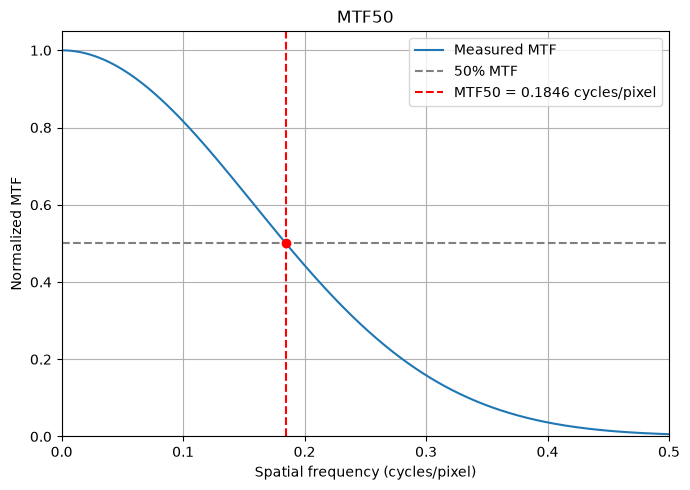

The analytic MTF50 = 0.1874 cycles per pixel
The measured MTF50 = 0.1846 cycles/pixel
The percent error = 1.4646661372169811%


In [10]:

# Find the first frequency where MTF <= 0.5
crossings = np.where(mtf_plot <= 0.5)[0]

if len(crossings) == 0:
    mtf50 = np.nan
    print("MTF50 was not reached in the measured frequency range.")
elif crossings[0] == 0:
    mtf50 = freq_plot[0]
else:
    # Linear interpolation between adjacent samples
    i = crossings[0]

    f1, f2 = freq_plot[i - 1], freq_plot[i]
    m1, m2 = mtf_plot[i - 1], mtf_plot[i]

    mtf50 = f1 + (0.5 - m1) * (f2 - f1) / (m2 - m1)

    

# Mark MTF50 on the plot
if np.isfinite(mtf50):
    plt.figure(figsize=(7, 5))
    plt.plot(freq_plot, mtf_plot, label="Measured MTF")
    plt.axhline(0.5, color="gray", linestyle="--", label="50% MTF")
    plt.axvline(mtf50, color="red", linestyle="--",
                label=f"MTF50 = {mtf50:.4f} cycles/pixel")
    plt.scatter([mtf50], [0.5], color="red", zorder=3)

    plt.xlabel("Spatial frequency (cycles/pixel)")
    plt.ylabel("Normalized MTF")
    plt.title("MTF50")
    plt.xlim(0, 0.5)
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Analytic result:
sigma = 1
def analytic_mtf50(sigma):
    return np.sqrt(np.log(2) / (2 * np.pi ** 2 * sigma ** 2))
print(f"The analytic MTF50 = {analytic_mtf50(sigma):.4f} cycles per pixel")
print(f"The measured MTF50 = {mtf50:.4f} cycles/pixel")
# percent error:
MTF50_sim = mtf50
error_percent = abs(MTF50_sim-analytic_mtf50(sigma))/analytic_mtf50(sigma)
print("The percent error = " + str(error_percent*100) + "%")

The percent error comparing a symulated edge with a gausian blur sigma = 1 mtf50 to the known analytic result for this blur is 1.46%, we determine that this is an acceptable agreement.

Next, we will repeat the MTF and MTF50 calculations on the captured raw image of a 7 degree slant edge target.

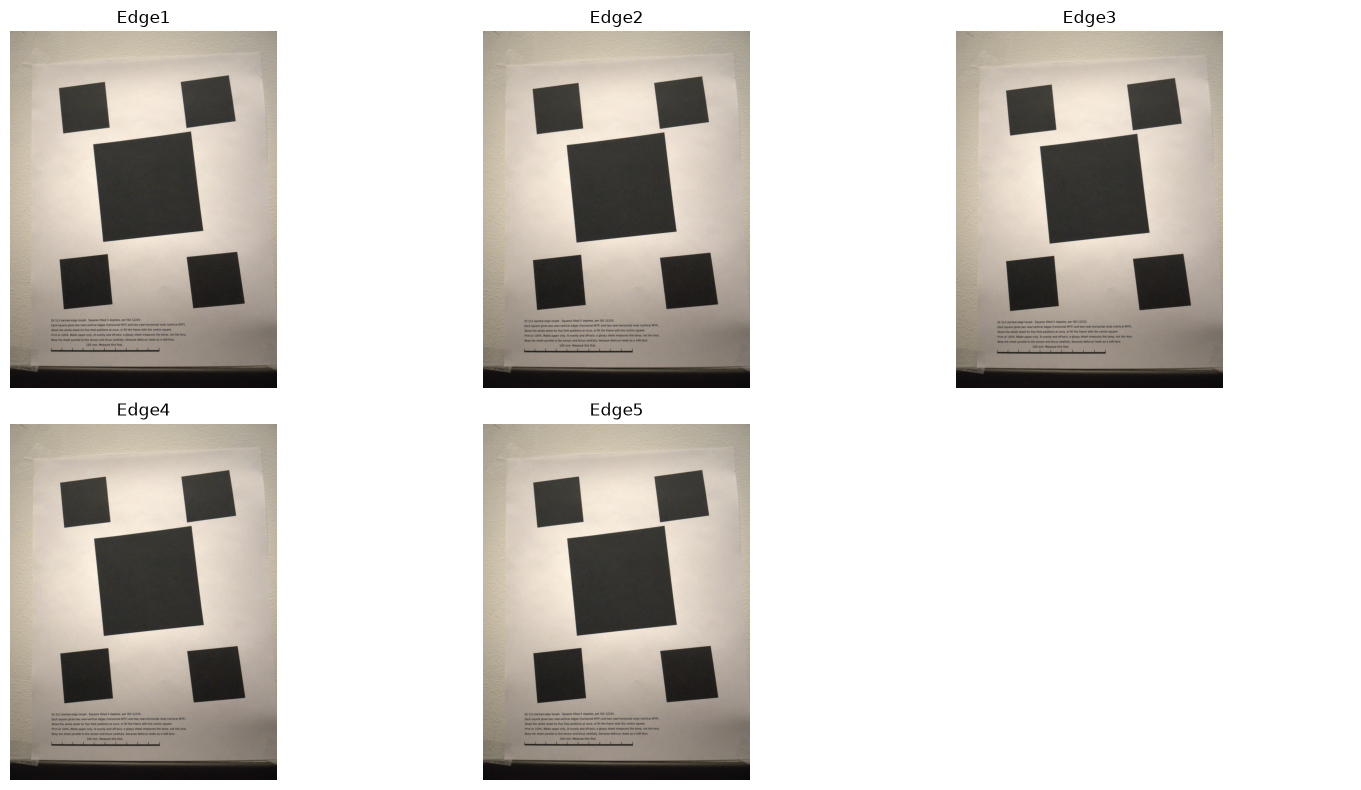

Edge1.dng: black=528, min=517, max=1984
Edge2.dng: black=528, min=513, max=1963
Edge3.dng: black=528, min=519, max=1955
Edge4.dng: black=528, min=515, max=2007
Edge5.dng: black=528, min=516, max=1990


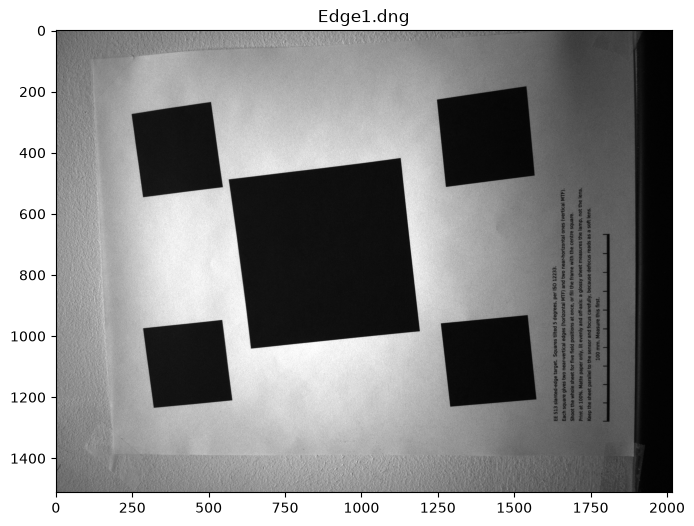

In [11]:
# load .dng raw captures and make contact sheet 

FOLDER = r"C:\Users\ammat\OneDrive\Documents\ee513\Images"
NAMES = [f"Edge{i}" for i in range(1, 6)]   # Edge1 ... Edge5
THUMB_MAX = 800                             # longest side of each thumbnail (px)
COLS = 3                                    # columns in the contact sheet
 
 
def load_dng(path, max_side=THUMB_MAX): #<- don't use this later (we dont want to demosaic) fine now to view
    """Demosaic a DNG to an 8-bit RGB array, downsized for display."""
    with rawpy.imread(path) as raw:
        rgb = raw.postprocess(
            use_camera_wb=True,
            half_size=True,        # fast: skips full-res demosaic
            no_auto_bright=False,
            output_bps=8,
        )
    img = Image.fromarray(rgb)
    img.thumbnail((max_side, max_side), Image.LANCZOS)
    return np.asarray(img)
 
 
images, labels = [], []
for name in NAMES:
    path = os.path.join(FOLDER, name + ".dng")
    if not os.path.exists(path):
        print(f"Missing: {path}")
        continue
    images.append(load_dng(path))
    labels.append(name)
 
if not images:
    raise SystemExit("No images loaded - check FOLDER and file names.")
 
rows = int(np.ceil(len(images) / COLS))
fig, axes = plt.subplots(rows, COLS, figsize=(5 * COLS, 4 * rows))
axes = np.atleast_1d(axes).ravel()
 
for ax, img, label in zip(axes, images, labels):
    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")
for ax in axes[len(images):]:
    ax.axis("off")                 # hide unused cells
 
plt.tight_layout()
plt.show()

# verification they are from the same camera:
import tifffile
from glob import glob

def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


FOLDER = r"C:\Users\ammat\OneDrive\Documents\ee513\Images"
my_capture_series = [os.path.join(FOLDER, f"Edge{i}.dng") for i in range(1, 6)]

ids = {lens_id(f) for f in my_capture_series}
assert len(ids) == 1, f"more than one camera in this series: {ids}"

Green_capture_list = []   # raw green values (DN), black level not yet subtracted
Linear_list = []          # black-subtracted, linear in scene radiance

for path in my_capture_series:
    with rawpy.imread(path) as raw:
        mosaic = raw.raw_image_visible.astype(np.float32)
        colors = raw.raw_colors_visible

        # Find where the first green pixel sits in the 2x2 Bayer tile (color index 1 = G)
        pattern = colors[:2, :2]
        r, c = np.argwhere(pattern == 1)[0]

        green = mosaic[r::2, c::2]                  # one green channel, half-res
        black = raw.black_level_per_channel[1]      # black level for green

    Green_capture_list.append(green)
    Linear_list.append(green - black)

    print(f"{os.path.basename(path)}: black={black}, "
          f"min={green.min():.0f}, max={green.max():.0f}")

# view the first image
img = Linear_list[0]

plt.figure(figsize=(8, 6))
plt.imshow(img, cmap="gray", vmin=0, vmax=np.percentile(img, 99.5))
#plt.colorbar(label="Linear DN (black-subtracted)")
plt.title(os.path.basename(my_capture_series[0]))
plt.axis("on")
plt.show()


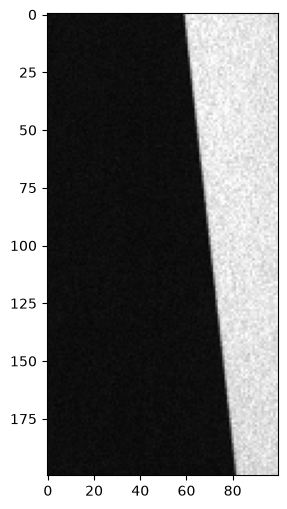

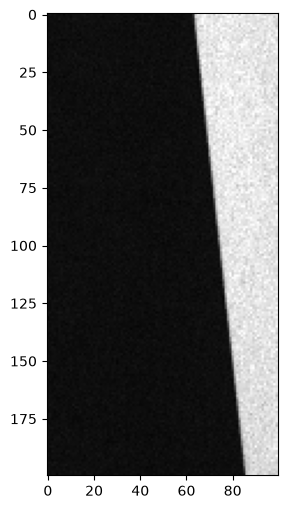

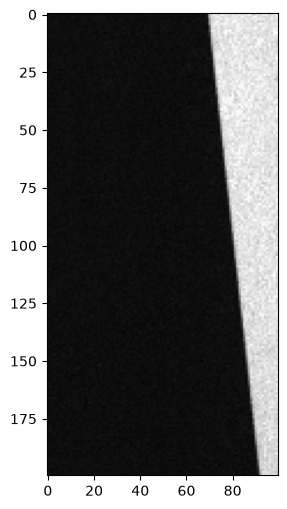

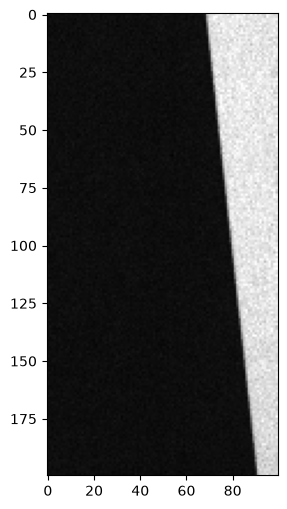

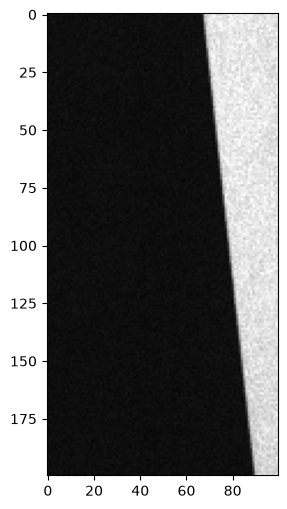

MTF50 per capture: [0.41047118 0.41066849 0.39646383 0.39839847 0.38485318]
Mean = 0.4001710280445089 ± 0.010814475938404086 cycles per green pixel
mean mtf50 realtive to nyquist (0.5) = 80.03420560890177%


In [12]:
# MTF center square:

center_MTF50_list, freq_list, mtf_list = [], [], []

for img in Linear_list:
    mtf50, freq, mtf = compute_mtf(img, 700, 900, 1100, 1200, show_crop=True)
    center_MTF50_list.append(mtf50)
    freq_list.append(freq)
    mtf_list.append(mtf)

mtf50_arr = np.array(center_MTF50_list)
print("MTF50 per capture:", mtf50_arr)
print(f"Mean = {np.nanmean(mtf50_arr)} ± {np.nanstd(mtf50_arr, ddof=1)} cycles per green pixel")
print(f"mean mtf50 realtive to nyquist (0.5) = {(np.nanmean(mtf50_arr)/0.5)*100}%")

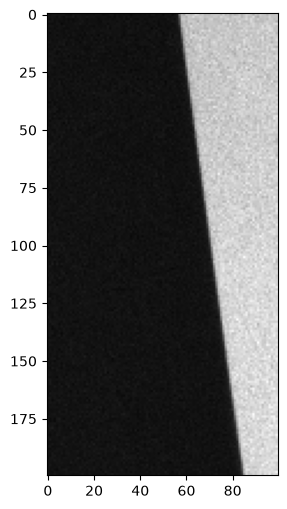

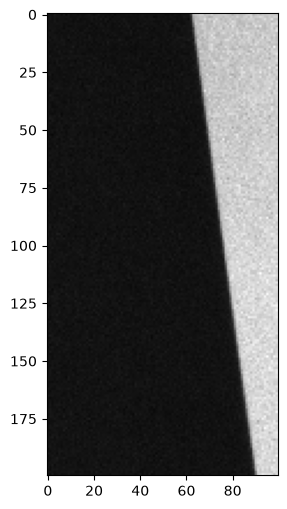

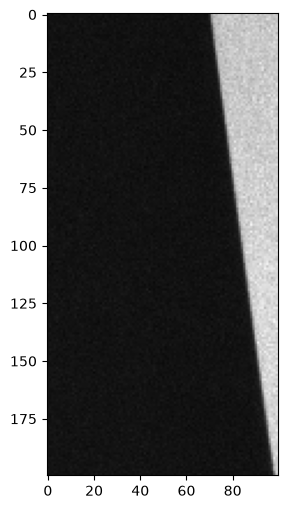

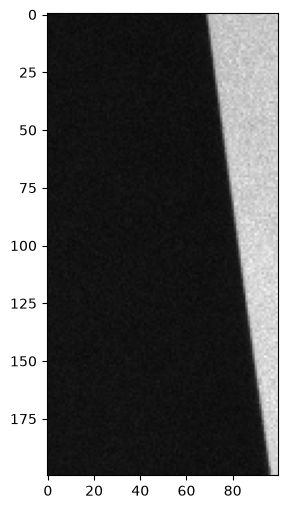

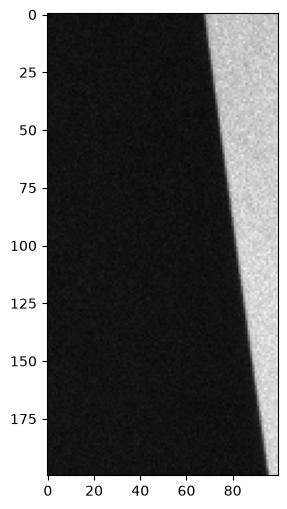

MTF50 per capture: [0.31568244 0.2934657  0.31722372 0.32141976 0.32573634]
Mean = 0.31470559416787364 ± 0.01250185613571148 cycles per green pixel
mean mtf50 realtive to nyquist (0.5) = 62.94111883357473%


In [13]:
# MTF upper left square:

ul_MTF50_list, freq_list, mtf_list = [], [], []

for img in Linear_list:
    mtf50, freq, mtf = compute_mtf(img, 300, 500, 460, 560, show_crop=True)
    ul_MTF50_list.append(mtf50)
    freq_list.append(freq)
    mtf_list.append(mtf)

mtf50_arr = np.array(ul_MTF50_list)
print("MTF50 per capture:", mtf50_arr)
print(f"Mean = {np.nanmean(mtf50_arr)} ± {np.nanstd(mtf50_arr, ddof=1)} cycles per green pixel")
print(f"mean mtf50 realtive to nyquist (0.5) = {(np.nanmean(mtf50_arr)/0.5)*100}%")

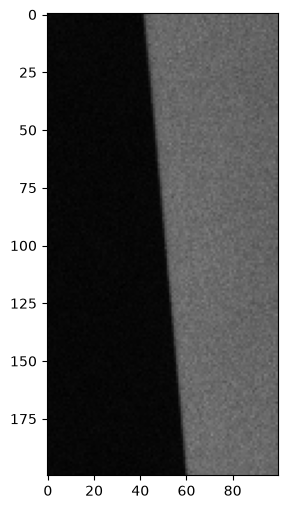

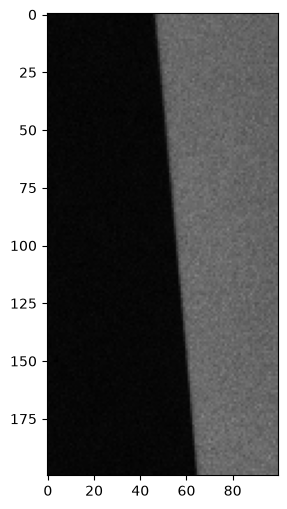

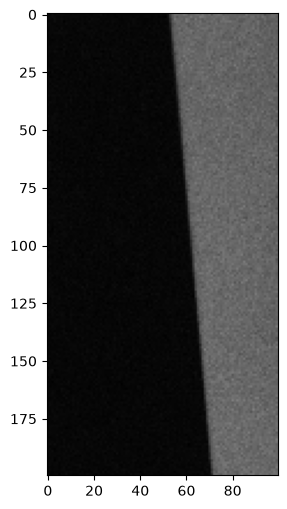

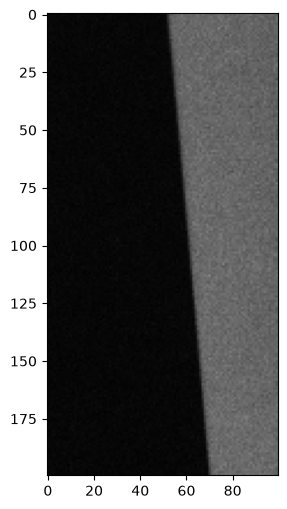

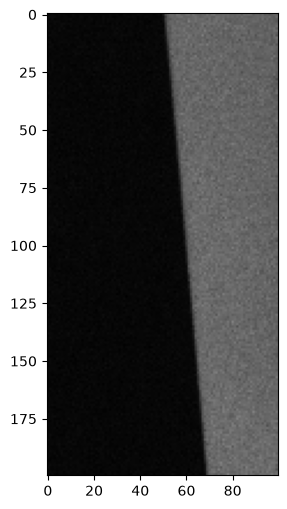

MTF50 per capture: [0.27505404 0.29694389 0.27999645 0.29263172 0.27300097]
Mean = 0.2835254147668672 ± 0.010700026682957466 cycles per green pixel
mean mtf50 realtive to nyquist (0.5) = 56.70508295337344%


In [14]:
# MTF upper right square:

ur_MTF50_list, freq_list, mtf_list = [], [], []

for img in Linear_list:
    mtf50, freq, mtf = compute_mtf(img, 200, 400, 1500, 1600, show_crop=True)
    ur_MTF50_list.append(mtf50)
    freq_list.append(freq)
    mtf_list.append(mtf)

mtf50_arr = np.array(ur_MTF50_list)
print("MTF50 per capture:", mtf50_arr)
print(f"Mean = {np.nanmean(mtf50_arr)} ± {np.nanstd(mtf50_arr, ddof=1)} cycles per green pixel")
print(f"mean mtf50 realtive to nyquist (0.5) = {(np.nanmean(mtf50_arr)/0.5)*100}%")

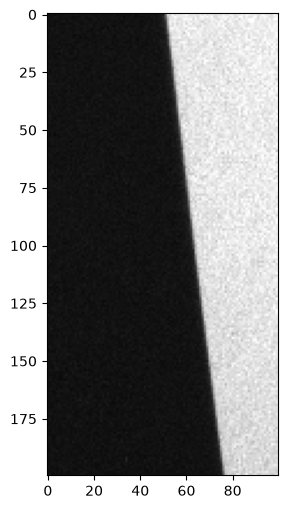

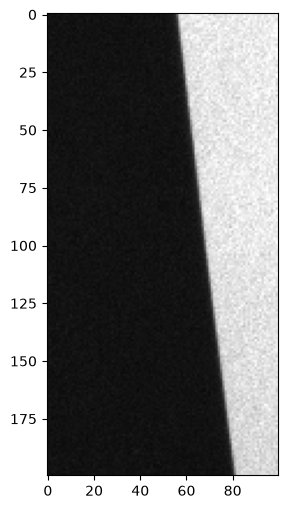

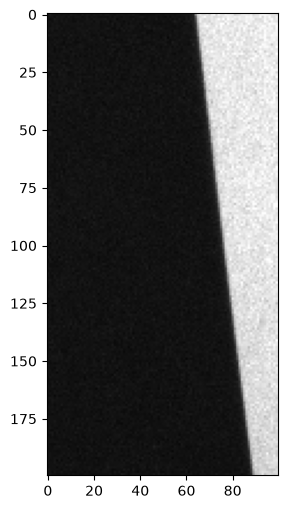

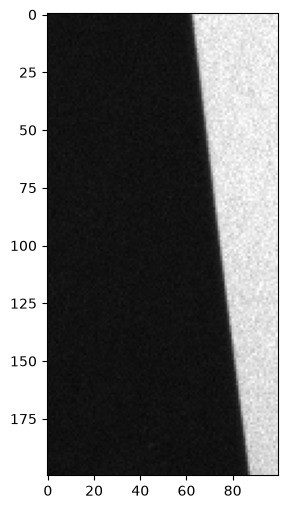

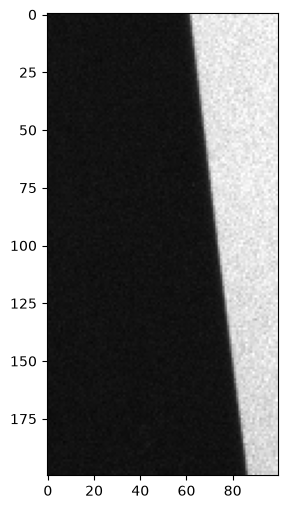

MTF50 per capture: [0.2767925  0.26372194 0.26151724 0.28481441 0.26551931]
Mean = 0.2704730802205532 ± 0.009949038683993933 cycles per green pixel
mean mtf50 realtive to nyquist (0.5) = 54.094616044110644%


In [15]:
# MTF lower left square:

ll_MTF50_list, freq_list, mtf_list = [], [], []

for img in Linear_list:
    mtf50, freq, mtf = compute_mtf(img, 1000, 1200, 500, 600, show_crop=True)
    ll_MTF50_list.append(mtf50)
    freq_list.append(freq)
    mtf_list.append(mtf)

mtf50_arr = np.array(ll_MTF50_list)
print("MTF50 per capture:", mtf50_arr)
print(f"Mean = {np.nanmean(mtf50_arr)} ± {np.nanstd(mtf50_arr, ddof=1)} cycles per green pixel")
print(f"mean mtf50 realtive to nyquist (0.5) = {(np.nanmean(mtf50_arr)/0.5)*100}%")

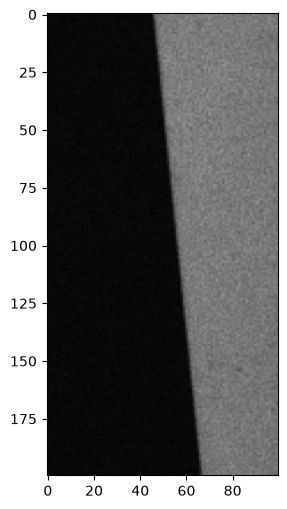

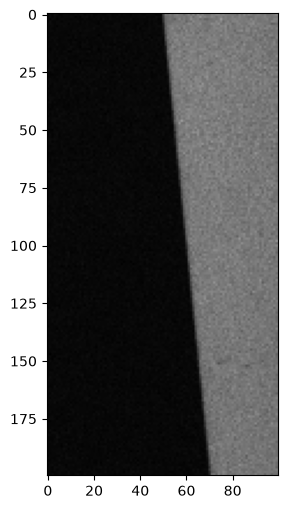

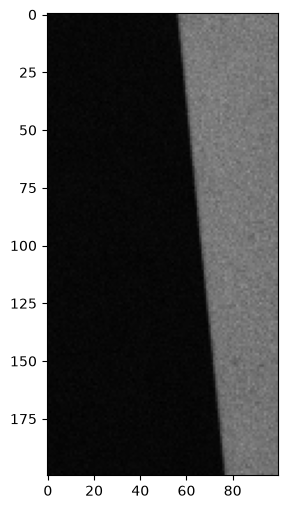

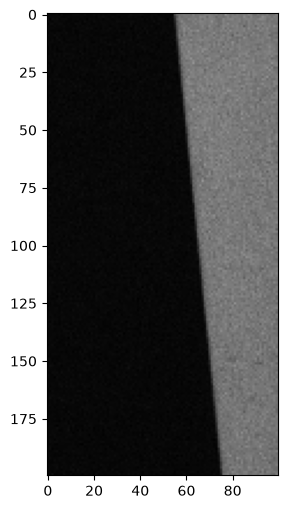

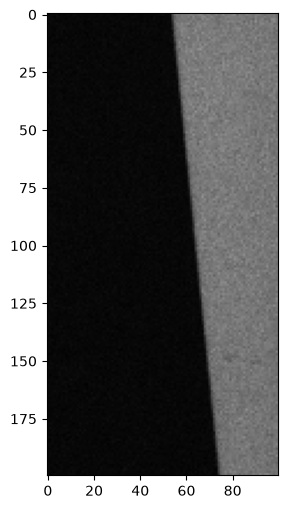

MTF50 per capture: [0.32047563 0.28652038 0.27697248 0.31061962 0.31670711]
Mean = 0.30225904477096155 ± 0.01934945529978815 cycles per green pixel
mean mtf50 realtive to nyquist (0.5) = 60.45180895419231%


In [16]:
# MTF lower right square:

lr_MTF50_list, freq_list, mtf_list = [], [], []

for img in Linear_list:
    mtf50, freq, mtf = compute_mtf(img, 950, 1150, 1500, 1600, show_crop=True)
    lr_MTF50_list.append(mtf50)
    freq_list.append(freq)
    mtf_list.append(mtf)

mtf50_arr = np.array(lr_MTF50_list)
print("MTF50 per capture:", mtf50_arr)
print(f"Mean = {np.nanmean(mtf50_arr)} ± {np.nanstd(mtf50_arr, ddof=1)} cycles per green pixel")
print(f"mean mtf50 realtive to nyquist (0.5) = {(np.nanmean(mtf50_arr)/0.5)*100}%")

Can we do some statistics comparing the locations: Is the mean MTF50 significantly different in the different locations?

In [17]:
import numpy as np
from scipy import stats
from itertools import combinations

groups = {
    "center": center_MTF50_list,
    "UL": ul_MTF50_list,
    "UR": ur_MTF50_list,
    "LL": ll_MTF50_list,
    "LR": lr_MTF50_list,
}
data = np.array(list(groups.values())).T      # shape (captures, squares)
n, k = data.shape

# Repeated-measures ANOVA (capture = subject)
grand = data.mean()
ss_square = n * np.sum((data.mean(axis=0) - grand) ** 2)
ss_subject = k * np.sum((data.mean(axis=1) - grand) ** 2)
ss_total = np.sum((data - grand) ** 2)
ss_error = ss_total - ss_square - ss_subject

df_square, df_error = k - 1, (k - 1) * (n - 1)
F = (ss_square / df_square) / (ss_error / df_error)
p = stats.f.sf(F, df_square, df_error)
print(f"RM-ANOVA: F({df_square},{df_error}) = {F:.3f}, p = {p}")

# Friedman test
print("Friedman:", stats.friedmanchisquare(*data.T))

# Post-hoc paired t-tests with Holm correction
pairs = list(combinations(groups, 2))
pvals = np.array([stats.ttest_rel(groups[a], groups[b]).pvalue for a, b in pairs])
order = np.argsort(pvals)
m = len(pvals)
p_adj = np.empty(m)
running_max = 0.0
for rank, idx in enumerate(order):
    running_max = max(running_max, (m - rank) * pvals[idx])
    p_adj[idx] = min(1.0, running_max)

for (a, b), p_raw, pa in zip(pairs, pvals, p_adj):
    print(f"{a} vs {b}: p={p_raw:.4f}, Holm-adj p={pa:.4f}")

RM-ANOVA: F(4,16) = 78.774, p = 2.56155068090236e-10
Friedman: FriedmanchisquareResult(statistic=np.float64(16.0), pvalue=np.float64(0.003019163651122605))
center vs UL: p=0.0009, Holm-adj p=0.0065
center vs UR: p=0.0000, Holm-adj p=0.0002
center vs LL: p=0.0000, Holm-adj p=0.0002
center vs LR: p=0.0007, Holm-adj p=0.0059
UL vs UR: p=0.0302, Holm-adj p=0.1210
UL vs LL: p=0.0016, Holm-adj p=0.0098
UL vs LR: p=0.1708, Holm-adj p=0.3417
UR vs LL: p=0.0942, Holm-adj p=0.2825
UR vs LR: p=0.1796, Holm-adj p=0.3417
LL vs LR: p=0.0091, Holm-adj p=0.0453


Result: The measured MTF50 differed significantly by location (ANOVA p-value <0.0001) and the Fiedman test agrees (p-value = 0.003). Using a holms correction for pair wise comparision all outer square differ significantly from the center square (P<= 0.0059). This result is consistent with the lens being 'softer' at teh corners. This could be due to the lens not correcting and having more aberations and worse performance around the edges. We can appreciate that the edge of the middel square appears sharper in the display edges. We can quantify this by comparing the mean mtf50 values to nyquist 0.5 (which is the highest spatial frequency before aliasing). The center square has an mtf50 frequency ( px/cycle of the green channel) of ~80% of the nyquist, while the peripheral squares are only ~50-60% of the mt50.

Statistics justification: Because each square location was measured within the same capture, the data have a repeated-measures structure, and each one is not truelly independent. Differences among locations were therefore tested with a oneway repeated-measures ANOVA (capture as subject), which removes variation between captures shared across locations and increases sensitivity relative to an unpaired analysis. Following a significant omnibus result(are there significant differences at all?), all ten pairwise comparisons between locations were made with paired t-tests, with Holm’s step-down procedure used to control the family-wise error rate at α = 0.05. Holm’s method was chosen because it is uniformly more powerful than Bonferroni and makes no additional assumptions about the dependence among tests. With only five captures, normality and sphericity cannot be reliably verified, so a Friedman test, a rank-based, distribution-free analogue of the repeated-measures ANOVA, was run as a confirmatory check on the omnibus result.

## Noise: the Poisson-Gaussian model.

Method dark fields:
1. Capture images (dng) with lens covered (capped)
2. f
3. f

Methods Photon Transfer Function:
1. aquire 5 pairs of images (lens covered with printer paper of a white background)
2. the images hsould span a range of exposure values
3. mean signal of each pair
4. varience of each pair
5. plot mean vs varience
6. fit a line to the linear region
7. slope (K) = conversion gain (DN), intercept gives you the read noise

Validation:
1. Generate camera sensor whit field data images (with a known gain and read noise it used to generate the frames)
2. Calculte the gain and read noise from the simulated flat white images using my photon transfer function code 
3. Compare calculated gain and read noise values to the true values used to create the images as a percent error
Manufacturer values:
1. get teh slope and intercept from the 

Load the relavent captures:

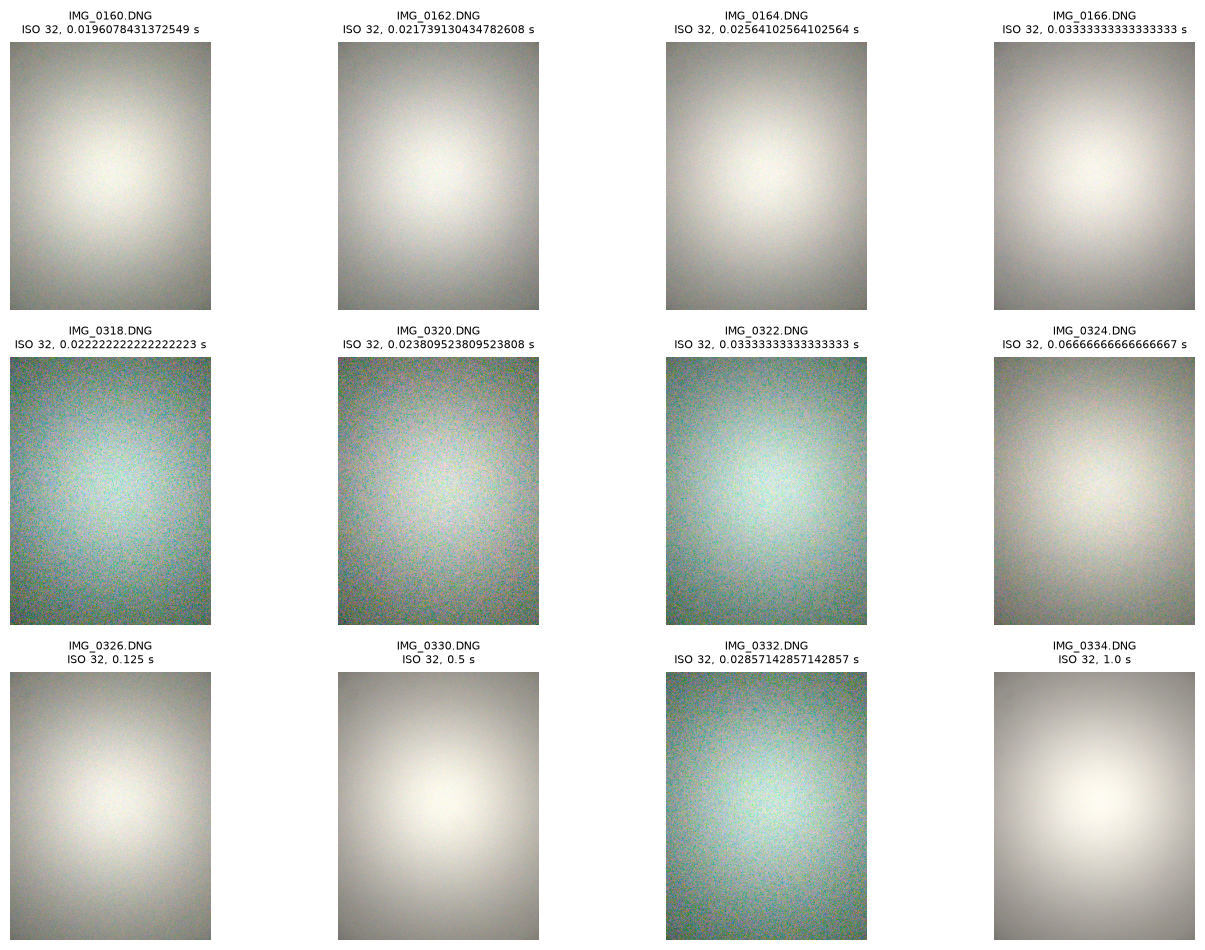

('iPhone 12 mini back camera 4.2mm f/1.6', 4.2, 26, (4032, 3024)): 24 files


In [18]:
# white fields:
FOLDER = r"C:\Users\ammat\Documents\Assigmnet3 Captures\old"
def get_exposure_iso(path):
    """Return (exposure_seconds, iso) for one DNG. Missing values come back as None."""
    with open(path, "rb") as f:
        tags = exifread.process_file(f, details=False)

    exp = tags.get("EXIF ExposureTime")
    exposure = float(exp.values[0].num) / float(exp.values[0].den) if exp else None

    iso_tag = tags.get("EXIF ISOSpeedRatings") or tags.get("EXIF PhotographicSensitivity")
    iso = int(iso_tag.values[0]) if iso_tag else None

    return exposure, iso
def show_contact_sheet(folder, step=2, cols=4, thumb_size=300, recursive=False):
    """Display a contact sheet of every `step`-th DNG in a folder."""
    pattern = "**/*" if recursive else "*"
    files = sorted(p for p in Path(folder).glob(pattern) if p.suffix.lower() == ".dng")
    files = files[::step]  # every other file (0, 2, 4, ...)

    if not files:
        print("No DNG files found.")
        return

    rows = math.ceil(len(files) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.2), squeeze=False)

    for ax in axes.flat:
        ax.axis("off")

    for ax, p in zip(axes.flat, files):
        with rawpy.imread(str(p)) as raw:
            # half_size skips demosaicing detail for speed; fine for thumbnails
            img = raw.postprocess(half_size=True, use_camera_wb=True, output_bps=8)

        # Shrink so the longest side is thumb_size px
        scale = max(1, max(img.shape[:2]) // thumb_size)
        ax.imshow(img[::scale, ::scale])

        exposure, iso = get_exposure_iso(p)
        ax.set_title(f"{p.name}\nISO {iso}, {exposure} s", fontsize=8)

    plt.tight_layout()
    plt.show()

show_contact_sheet(FOLDER)

# confrim they are from the same camera:
import tifffile
from glob import glob
from collections import defaultdict

def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))

# every DNG in the folder (case-insensitive, so .dng and .DNG both match)
all_captures = sorted(p for p in Path(FOLDER).glob("*") if p.suffix.lower() == ".dng")
assert all_captures, f"No DNG files found in {FOLDER}"

by_id = defaultdict(list)
for f in all_captures:
    by_id[lens_id(f)].append(f.name)

for ident, names in by_id.items():
    print(f"{ident}: {len(names)} files")

assert len(by_id) == 1, (
    "more than one camera/lens configuration in this folder:\n"
    + "\n".join(f"  {ident}: {names}" for ident, names in by_id.items())
)

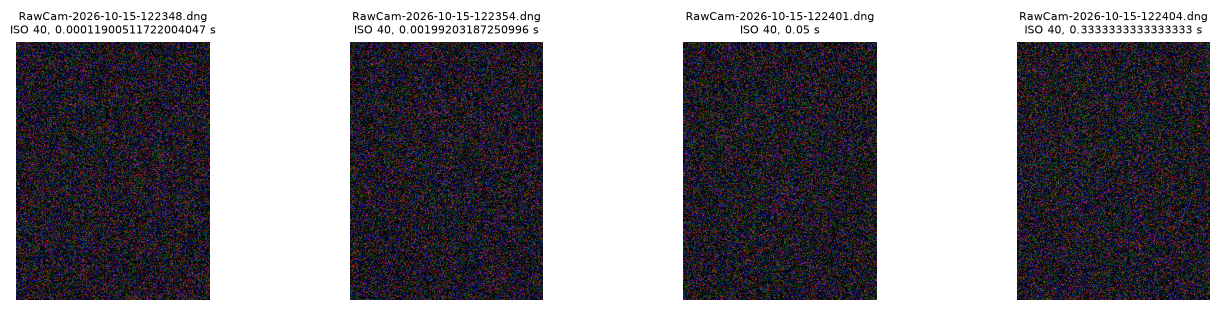

('iPhone 12 mini back camera 4.2mm f/1.6', 4.2, 26, (4032, 3024)): 4 files


In [19]:
# Black frames:
FOLDER_black = r"C:\Users\ammat\Documents\Assigmnet3 Captures\BlackFrame"

show_contact_sheet(FOLDER_black,step = 1)
# confrim they are from the same camera:

# every DNG in the folder (case-insensitive, so .dng and .DNG both match)
all_captures = sorted(p for p in Path(FOLDER_black).glob("*") if p.suffix.lower() == ".dng")
assert all_captures, f"No DNG files found in {FOLDER}"

by_id = defaultdict(list)
for f in all_captures:
    by_id[lens_id(f)].append(f.name)

for ident, names in by_id.items():
    print(f"{ident}: {len(names)} files")

assert len(by_id) == 1, (
    "more than one camera/lens configuration in this folder:\n"
    + "\n".join(f"  {ident}: {names}" for ident, names in by_id.items())
)

Verify the back level from the capped captures and compare to the value listed in the files from the manufacture.

In [20]:
def report_black_levels(folder, recursive=False):
    """Print the black level (per channel) and white level for every DNG in a folder."""
    pattern = "**/*" if recursive else "*"
    files = sorted(p for p in Path(folder).glob(pattern) if p.suffix.lower() == ".dng")

    results = {}
    for p in files:
        with rawpy.imread(str(p)) as raw:
            black = list(raw.black_level_per_channel)  # one value per CFA channel (e.g. R, G1, B, G2)
            white = raw.white_level
            pattern_str = "".join("RGBG"[i] if i < 4 else "?" for i in raw.raw_pattern.flatten()) \
                if raw.raw_pattern is not None else "n/a"

        results[p.name] = {"black_level": black, "white_level": white}
        print(f"{p.name:<30} black: {black}   white: {white}")
    return results

report_black_levels(FOLDER_black)

#measure black levels from the images
def measure_dark_level(path):
    """Mean raw value per CFA channel; for a dark frame this approximates the black level."""
    with rawpy.imread(str(path)) as raw:
        data = raw.raw_image_visible.astype(float)
        colors = raw.raw_colors_visible
        return {int(c): data[colors == c].mean() for c in np.unique(colors)}

files = sorted(p for p in Path(FOLDER_black).glob("*") if p.suffix.lower() == ".dng")
assert files, f"No DNG files found in {FOLDER}"

dark_levels = []                                    # one dict per file: {channel_index: mean DN}
for f in files:
    dark_levels.append(measure_dark_level(f))

# stack into an array of shape (n_files, n_channels)
channels = sorted(dark_levels[0].keys())
levels = np.array([[d[c] for c in channels] for d in dark_levels])

print(f"{len(files)} files, channels {channels}")
for i, c in enumerate(channels):
    print(f"Channel {c}: mean = {levels[:, i].mean():.3f} DN, std = {levels[:, i].std(ddof=1):.3f} DN")

overall = levels.mean(axis=1)                       # one number per file (average of the channels)
print(f"All channels combined: mean = {overall.mean():.3f} DN, std = {overall.std(ddof=1):.3f} DN")

RawCam-2026-10-15-122348.dng   black: [528, 528, 528, 528]   white: 4095
RawCam-2026-10-15-122354.dng   black: [528, 528, 528, 528]   white: 4095
RawCam-2026-10-15-122401.dng   black: [528, 528, 528, 528]   white: 4095
RawCam-2026-10-15-122404.dng   black: [528, 528, 528, 528]   white: 4095
4 files, channels [0, 1, 2, 3]
Channel 0: mean = 527.747 DN, std = 0.082 DN
Channel 1: mean = 527.687 DN, std = 0.041 DN
Channel 2: mean = 527.796 DN, std = 0.023 DN
Channel 3: mean = 527.687 DN, std = 0.040 DN
All channels combined: mean = 527.729 DN, std = 0.044 DN


The manufacturer repots a dark level of 528, we measure a mean dark level of 527.729 DN, std = 0.044 DN. The manufacturer value is with in one standared deviation of our calculated value. This is acceptable. I will use a dark value of 527.687 DN, because this is the mean of the first green channel of our captures and I work in the green channel for the work bellow. 

Generate white fields with known gain and read values:

22 exposure levels, two frames each, 128 x 128 px


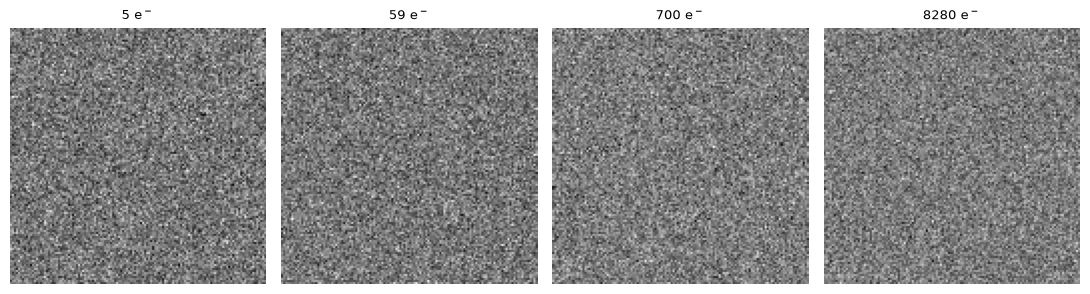

simulated pairs K = 0.4236 DN/e-
simulated pairs read noise = 2.9602 e-
truth                   K = 0.4266 DN/e-            read noise =  2.80 e-
K percent error: -0.6900710419780219%
read percent error: 5.721657632477197%


In [21]:
# Simulated sensor from lecture 5:

PRNU = 0.012          # 1.2 percent per-pixel gain variation, fixed for this sensor

def flat_pair(electrons, level_index):
    """Two independent frames at the same illumination."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=PRNU)
    return a.astype(float), b.astype(float)

levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
pairs = [flat_pair(e, i) for i, e in enumerate(levels)]
print(f"{len(pairs)} exposure levels, two frames each, 128 x 128 px")

fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for ax, i in zip(axes, [0, 7, 14, 21]):
    a, _ = pairs[i]
    ax.imshow(a, cmap="gray")
    ax.set_title(f"{levels[i]:.0f} e$^-$", fontsize=9.5)
    ax.axis("off")
plt.tight_layout(); plt.show()

# Do the Photon transfer curve calculations:

# fit function:
def fit_ptc(mean, var, frac=0.7):
    """Fit the linear region, below `frac` of saturation."""
    ok = mean < (psu.WHITE_LEVEL - psu.BLACK_LEVEL) * frac
    slope, intercept = np.polyfit(mean[ok], var[ok], 1)
    return slope, intercept, ok

# get the mean and var of the all the A and B pairs <- created by the code above this

def PTC_calculations(pairs):
    means, var_single, var_pair = [], [], []
    for a, b in pairs:
        means.append((a.mean() + b.mean()) / 2 - psu.BLACK_LEVEL)
        # need to mean   
        var_pair.append(np.var(a - b) / 2)
    return means, var_pair

means, v = PTC_calculations(pairs)
means = np.asarray(means, dtype=float)
v = np.asarray(v, dtype=float)

# fit the model from class to the mean and var data:
K, c, _ = fit_ptc(means, v)
read = np.sqrt(max(c,0))/K

print(f"simulated pairs K = {K:.4f} DN/e-")
print(f"simulated pairs read noise = {read:.4f} e-")

# from the lecture notebook: ground truth values: 
TRUE_K = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL     # DN per electron
TRUE_READ = psu.READ_NOISE                                        # electrons RMS
print(f"{'truth':22s}  K = {TRUE_K:.4f} DN/e-            read noise = {TRUE_READ:5.2f} e-")

# percentage error:
K_percentageError = ((K-TRUE_K)/TRUE_K) * 100
print("K percent error: " + str(K_percentageError) + "%")
# percentage error read function:
Read_percentError = ((read- TRUE_READ)/TRUE_READ)*100
print("read percent error: " + str(Read_percentError) + "%")

This gives us a measurement of if our PTC code is working correctly. Verification passed for this step.

In [22]:
FOLDER = r"C:\Users\ammat\Documents\Assigmnet3 Captures\old"
PATCH = 128 # use patchs of the center of the images
B_level = 527.687
def load_green_plane(path):
    """Return the first green (G1) sub-image of the Bayer mosaic as a 2D float array."""
    with rawpy.imread(str(path)) as raw:
        img = raw.raw_image_visible.astype(np.float64)   # float avoids uint16 wraparound in a - b
        colors = raw.raw_colors_visible
        desc = raw.color_desc.decode()                    # e.g. "RGBG"
    # find the first green site inside the 2x2 Bayer cell
    for r in range(2):
        for c in range(2):
            if desc[colors[r, c]] == "G":
                return img[r::2, c::2]
    raise ValueError("No green pixel found in the 2x2 cell")

def load_center_patch(path, size=PATCH):
    """Center size x size crop of the G1 plane, returned as a 2D array."""
    g = load_green_plane(path)
    rows, cols = g.shape
    r0 = rows // 2 - size // 2
    c0 = cols // 2 - size // 2
    return g[r0:r0 + size, c0:c0 + size]

def show_patches(files, step=2, cols=5):
    """Display the G1 center patch of every `step`-th file (step=2 -> first frame of each pair)."""
    selected = files[::step]
    rows = int(np.ceil(len(selected) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, p in zip(axes.flat, selected):
        patch = load_center_patch(p)
        ax.imshow(patch, cmap="gray")
        ax.set_title(f"{p.name}\nmean {patch.mean():.0f} DN", fontsize=8)
    plt.tight_layout()
    plt.show()

def PTC_calculations(pairs, black_level=B_level):
    means, var_pair, n_pixels = [], [], []
    for a, b in pairs:
        means.append((a.mean() + b.mean()) / 2 - black_level)
        var_pair.append(np.var(a - b) / 2)   # differencing cancels fixed-pattern noise
        n_pixels.append(a.size)              # pixels per patch
        
    return means, var_pair, n_pixels

# --- build the pairs ---
files = sorted(p for p in Path(FOLDER).glob("*") if p.suffix.lower() == ".dng")
assert len(files) % 2 == 0, f"Odd number of files ({len(files)}), pairs won't line up"
#show_patches(files)
# black/white levels from the files themselves
with rawpy.imread(str(files[0])) as raw:
    BLACK = float(np.mean(raw.black_level_per_channel))
    WHITE = float(raw.white_level)
#print(f"Black level: {BLACK}, white level: {WHITE}")

capturePairs, pairSettings = [], []
for f1, f2 in zip(files[0::2], files[1::2]):
    s1, s2 = get_exposure_iso(f1), get_exposure_iso(f2)
    #print(get_exposure_iso(f1), get_exposure_iso(f2)) # make sure that the exposure pairs match
    if s1 != s2:
        print(f"WARNING: settings differ for {f1.name} / {f2.name}: {s1} vs {s2}")
        
    a, b = load_center_patch(f1), load_center_patch(f2)
    assert a.shape == b.shape == (PATCH, PATCH), f"Unexpected patch shape for {f1.name}: {a.shape}, {b.shape}"
    capturePairs.append((a, b))
    pairSettings.append(s1)

# --- compute and report ---
means, var_pair, n_pixels = PTC_calculations(capturePairs, black_level=B_level)

print(f"{'Pair':<5}{'Exposure':>10}{'ISO':>6}{'Mean (DN)':>13}{'Var (DN^2)':>13}{'Pixels':>9}")
for i, ((exp, iso), m, v, n) in enumerate(zip(pairSettings, means, var_pair, n_pixels), 1):
    print(f"{i:<5}{exp:>10.4f}{str(iso):>6}{m:>13.2f}{v:>13.2f}{n:>9}")

Pair   Exposure   ISO    Mean (DN)   Var (DN^2)   Pixels
1        0.0196    32       197.14        82.75    16384
2        0.0217    32       218.80        90.55    16384
3        0.0256    32       258.57       105.47    16384
4        0.0333    32       333.08       133.59    16384
5        0.0222    32        29.23        14.81    16384
6        0.0238    32        31.99        15.85    16384
7        0.0333    32        40.81        18.97    16384
8        0.0667    32        82.34        33.28    16384
9        0.1250    32       163.33        67.24    16384
10       0.5000    32       640.86       267.11    16384
11       0.0286    32        35.70        17.80    16384
12       1.0000    32      2732.84      1346.89    16384


value for read2.817274500605894
Points used in fit: 11 of 12 (excluded: 1)
Gain K       = 0.4099 ± 0.0038 DN/e-
Intercept    = 1.33 ± 0.97 DN^2
Read noise   = 2.82 ± 1.05 e-


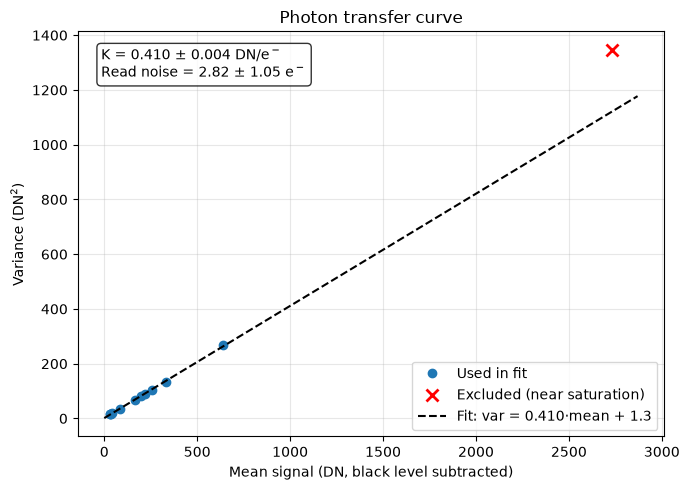

In [23]:
# fit line to linear portion of the data:
def fit_ptc(mean, var, frac=0.7): # update to inclide uncertainty measures
    """Fit var = K*mean + b over points below `frac` of saturation. Returns fit, covariance, mask."""
    ok = mean < (4095.0 - B_level) * frac
    (slope, intercept), cov = np.polyfit(mean[ok], var[ok], 1, cov=True)
    return slope, intercept, cov, ok

means = np.asarray(means, dtype=float)
var_pair = np.asarray(var_pair, dtype=float)

slope, intercept, cov, ok = fit_ptc(means, var_pair)

# gain K in DN/e-, with 1-sigma uncertainty from the fit
K = slope
sK = np.sqrt(cov[0, 0])
sb = np.sqrt(cov[1, 1])

# read noise in electrons: sqrt(intercept) / K, propagated with the slope-intercept covariance
read = np.sqrt(max(intercept, 0)) / K
#print(read)
print("value for read" + str(read))
if intercept > 0:
    dK = -np.sqrt(intercept) / K**2
    db = 1 / (2 * K * np.sqrt(intercept))
    s_read = np.sqrt(db**2 * sb**2 + dK**2 * sK**2 + 2 * db * dK * cov[0, 1])
else:
    s_read = np.nan  # intercept <= 0: read noise isn't resolvable from this fit

print(f"Points used in fit: {ok.sum()} of {len(ok)} (excluded: {(~ok).sum()})")
print(f"Gain K       = {K:.4f} ± {sK:.4f} DN/e-")
print(f"Intercept    = {intercept:.2f} ± {sb:.2f} DN^2")
print(f"Read noise   = {read:.2f} ± {s_read:.2f} e-")

# figure
x = np.linspace(0, means.max() * 1.05, 200)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(means[ok], var_pair[ok], "o", label="Used in fit")
ax.plot(means[~ok], var_pair[~ok], "x", color="red", ms=9, mew=2, label="Excluded (near saturation)")
ax.plot(x, K * x + intercept, "k--",
        label=f"Fit: var = {K:.3f}·mean + {intercept:.1f}")
ax.set_xlabel("Mean signal (DN, black level subtracted)")
ax.set_ylabel("Variance (DN$^2$)")
ax.set_title("Photon transfer curve")
ax.text(0.04, 0.96,
        f"K = {K:.3f} ± {sK:.3f} DN/e$^-$\nRead noise = {read:.2f} ± {s_read:.2f} e$^-$",
        transform=ax.transAxes, va="top", bbox=dict(boxstyle="round", fc="white", alpha=0.8))
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


Plot SNR curve vs single

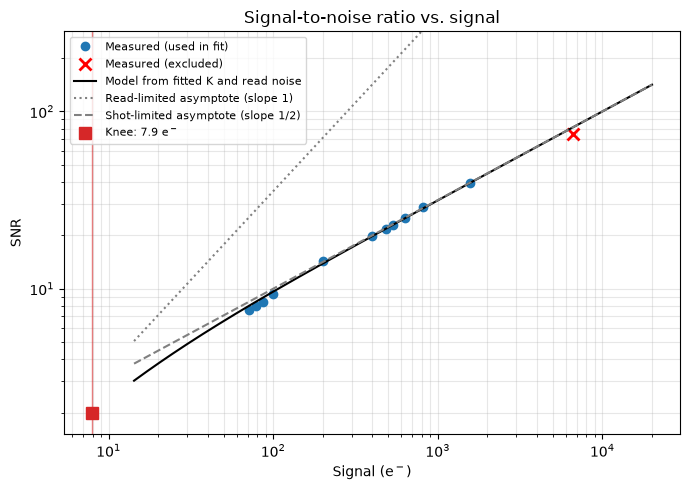

Knee = 7.9 ± 5.1 e-  (read noise = 2.82 e-)
Measured signal range: 71.3 to 6668 e-
Reaches read-limited regime (signal below knee): False
Reaches shot-limited regime (signal above knee): True


In [24]:
K = slope                                  # DN/e-
read_e = np.sqrt(intercept) / K            # read noise, e-
knee_e = read_e**2                         # signal where shot variance = read variance

# measured data
S_e = means / K                            # signal in electrons
snr = means / np.sqrt(var_pair)            # unitless, so same in DN or e-

# model: SNR = S / sqrt(S + r^2)
S_model = np.logspace(np.log10(S_e.min() / 5), np.log10(S_e.max() * 3), 400)
snr_model = S_model / np.sqrt(S_model + read_e**2)
knee_snr = knee_e / np.sqrt(knee_e + read_e**2)

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(S_e[ok], snr[ok], "o", label="Measured (used in fit)")
if (~ok).any():
    ax.loglog(S_e[~ok], snr[~ok], "x", color="red", ms=9, mew=2, label="Measured (excluded)")
ax.loglog(S_model, snr_model, "k-", label="Model from fitted K and read noise")
ax.loglog(S_model, S_model / read_e, ":", color="gray", label="Read-limited asymptote (slope 1)")
ax.loglog(S_model, np.sqrt(S_model), "--", color="gray", label="Shot-limited asymptote (slope 1/2)")
ax.axvline(knee_e, color="C3", lw=1, alpha=0.6)
ax.plot(knee_e, knee_snr, "s", color="C3", ms=9, label=f"Knee: {knee_e:.1f} e$^-$")
ax.set_xlabel("Signal (e$^-$)")
ax.set_ylabel("SNR")
ax.set_title("Signal-to-noise ratio vs. signal")
ax.set_ylim(snr_model.min() / 2, snr_model.max() * 2)
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

# knee uncertainty from the fit covariance
rng = np.random.default_rng(0)
d = rng.multivariate_normal([slope, intercept], cov, size=20000)
d = d[(d[:, 0] > 0) & (d[:, 1] > 0)]
knee_draws = d[:, 1] / d[:, 0]**2
print(f"Knee = {knee_e:.1f} ± {knee_draws.std():.1f} e-  (read noise = {read_e:.2f} e-)")

# do the captures reach both regimes?
print(f"Measured signal range: {S_e.min():.1f} to {S_e.max():.0f} e-")
print("Reaches read-limited regime (signal below knee):", S_e.min() < knee_e)
print("Reaches shot-limited regime (signal above knee):", S_e.max() > knee_e)

Check the vendors noise model to compare:

In [25]:
def get_noise_profile_tifffile(path):
    with tifffile.TiffFile(path) as tif:
        stack = list(tif.pages)
        while stack:
            page = stack.pop()
            tag = page.tags.get(51041)           # NoiseProfile
            if tag is not None:
                return list(tag.value)
            sub = getattr(page, "pages", None)   # SubIFDs, if this tifffile version exposes them
            if sub is not None:
                stack.extend(list(sub))
    return None

get_noise_profile_tifffile(files[10]) #<- this gives you the intercept and slope of the manufacture noise profile

[2.8413910420900002e-05, 2.42434125376e-07]

In [26]:
# convert using our white level - dark level (it is currently noramlized to 0-1)
profile = get_noise_profile_tifffile(files[10])
S, O = profile[0], profile[1]            # first plane; compare the other planes too
rng_dn = WHITE - B_level

K_equiv = rng_dn * S                      # variance slope in DN^2 per DN, i.e. gain K
b_equiv = rng_dn**2 * O                   # intercept in DN^2
read_e_equiv = np.sqrt(b_equiv) / K_equiv

print(f"Manufacturer model: K = {K_equiv:.4f} DN/e-, intercept = {b_equiv:.2f} DN^2, "
      f"read noise = {read_e_equiv:.2f} e-")
print(f"My fit:           K = {slope:.4f} DN/e-, intercept = {intercept:.2f} DN^2, "
      f"read noise = {np.sqrt(intercept)/slope:.2f} e-")

Manufacturer model: K = 0.1014 DN/e-, intercept = 3.09 DN^2, read noise = 17.33 e-
My fit:           K = 0.4099 DN/e-, intercept = 1.33 DN^2, read noise = 2.82 e-


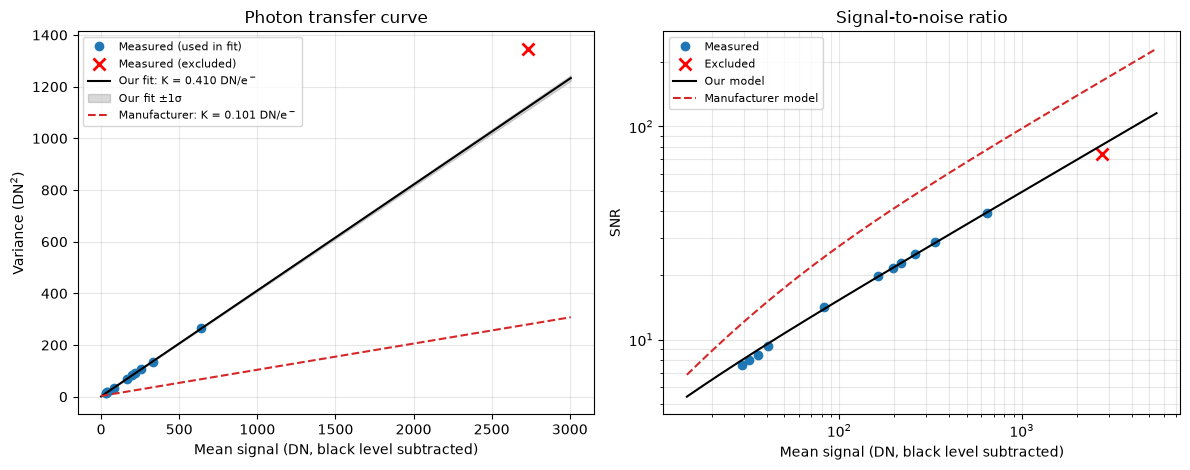

                 K (DN/e-)    Intercept (DN^2)   Read noise (e-)
My fit              0.4099                1.33              2.82
Manufacturer        0.1014                3.08             17.33


In [27]:
#figure to compare the two curves

# --- manufacturer model, converted to DN units ---
S_mfr, O_mfr = get_noise_profile_tifffile(files[0])
with rawpy.imread(str(files[0])) as raw:
    white_tag = float(raw.white_level)      # use the file's WhiteLevel tag, not your observed clip level
rng_dn = white_tag - BLACK
K_mfr = rng_dn * S_mfr                      # DN/e-
b_mfr = rng_dn**2 * O_mfr                   # DN^2

# --- evaluate both models ---
x = np.linspace(0, means.max() * 1.1, 300)
var_fit = slope * x + intercept
band = np.sqrt(x**2 * cov[0, 0] + 2 * x * cov[0, 1] + cov[1, 1])   # 1-sigma uncertainty of the fitted line
var_mfr = K_mfr * x + b_mfr

xl = np.logspace(np.log10(means.min() / 2), np.log10(means.max() * 2), 300)
snr_fit = xl / np.sqrt(np.maximum(slope * xl + intercept, 1e-12))
snr_mfr = xl / np.sqrt(K_mfr * xl + b_mfr)
snr_data = means / np.sqrt(var_pair)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# left: photon transfer curve
ax1.plot(means[ok], var_pair[ok], "o", label="Measured (used in fit)")
if (~ok).any():
    ax1.plot(means[~ok], var_pair[~ok], "x", color="red", ms=9, mew=2, label="Measured (excluded)")
ax1.plot(x, var_fit, "k-", label=f"Our fit: K = {slope:.3f} DN/e$^-$")
ax1.fill_between(x, var_fit - band, var_fit + band, color="k", alpha=0.15, label="Our fit ±1σ")
ax1.plot(x, var_mfr, "C3--", label=f"Manufacturer: K = {K_mfr:.3f} DN/e$^-$")
ax1.set_xlabel("Mean signal (DN, black level subtracted)")
ax1.set_ylabel("Variance (DN$^2$)")
ax1.set_title("Photon transfer curve")
ax1.grid(alpha=0.3); ax1.legend(fontsize=8)

# right: SNR vs signal (unitless, so it's the same in DN or e-)
ax2.loglog(means[ok], snr_data[ok], "o", label="Measured")
if (~ok).any():
    ax2.loglog(means[~ok], snr_data[~ok], "x", color="red", ms=9, mew=2, label="Excluded")
ax2.loglog(xl, snr_fit, "k-", label="Our model")
ax2.loglog(xl, snr_mfr, "C3--", label="Manufacturer model")
ax2.set_xlabel("Mean signal (DN, black level subtracted)")
ax2.set_ylabel("SNR")
ax2.set_title("Signal-to-noise ratio")
ax2.grid(alpha=0.3, which="both"); ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

# --- numbers side by side ---
print(f"{'':<14}{'K (DN/e-)':>12}{'Intercept (DN^2)':>20}{'Read noise (e-)':>18}")
print(f"{'My fit':<14}{slope:>12.4f}{intercept:>20.2f}{np.sqrt(max(intercept, 0)) / slope:>18.2f}")
print(f"{'Manufacturer':<14}{K_mfr:>12.4f}{b_mfr:>20.2f}{np.sqrt(b_mfr) / K_mfr:>18.2f}")

Our model and the manufacturer results are very different. However, because we meaured ours directly on the raw captures I will use ours. For theirs we have to assumes it is for the same iso settings as we did but I do not see a way to confirm, we also do not know what other assumptions were used on theirs, we also can not get an uncertianty value for their fit. We also (as far as I know) do not know if they do other processing on the images to calculate the manufacture curve, we are just using the raw files which should be the correct approach.

Dark current from the capped frames:

Frames: 4 at 4 exposure times
Slope     = 0.2504 ± 0.0464 DN/s
Intercept = 527.66 ± 0.01 DN
Dark current = 0.611 ± 0.113 e-/s  (using K = 0.4099 DN/e-)


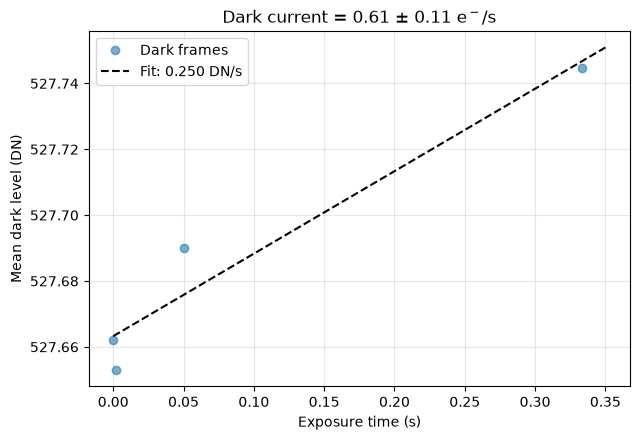

In [32]:
# folder with the dark frames is where?
FOLDER_Dark = r"C:\Users\ammat\Documents\Assigmnet3 Captures\BlackFrame"

def dark_current_fit(folder, K, sK, black_level=None):
    """Fit mean dark level vs exposure time; convert slope (DN/s) to e-/s using gain K (DN/e-)."""
    files = sorted(p for p in Path(folder).glob("*") if p.suffix.lower() == ".dng")

    t, m = [], []
    for p in files:
        exposure, iso = get_exposure_iso(p)
        t.append(float(Fraction(exposure)))          # '1/120' -> seconds
        m.append(load_green_plane(p).mean())         # whole G1 plane: more pixels, tighter mean
    t, m = np.array(t), np.array(m)

    (slope_dn, icpt), cov = np.polyfit(t, m, 1, cov=True)
    s_slope = np.sqrt(cov[0, 0])

    dc = slope_dn / K                                # e-/s
    s_dc = abs(dc) * np.sqrt((s_slope / slope_dn)**2 + (sK / K)**2) if slope_dn != 0 else np.nan

    print(f"Frames: {len(t)} at {len(np.unique(t))} exposure times")
    print(f"Slope     = {slope_dn:.4f} ± {s_slope:.4f} DN/s")
    print(f"Intercept = {icpt:.2f} ± {np.sqrt(cov[1, 1]):.2f} DN" )
    print(f"Dark current = {dc:.3f} ± {s_dc:.3f} e-/s  (using K = {K:.4f} DN/e-)")
    if abs(slope_dn) < 2 * s_slope:
        print(f"Slope is within 2σ of zero: report an upper bound of about {(slope_dn + 2 * s_slope) / K:.3f} e-/s")

    # figure
    xs = np.linspace(0, t.max() * 1.05, 100)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(t, m, "o", alpha=0.6, label="Dark frames")
    ax.plot(xs, slope_dn * xs + icpt, "k--", label=f"Fit: {slope_dn:.3f} DN/s")
    ax.set_xlabel("Exposure time (s)")
    ax.set_ylabel("Mean dark level (DN)")
    ax.set_title(f"Dark current = {dc:.2f} ± {s_dc:.2f} e$^-$/s")
    ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()
    return dc, s_dc

dc, s_dc = dark_current_fit(FOLDER_Dark, K=slope, sK=np.sqrt(cov[0, 0]), black_level=B_level)

